In [1]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
# Dataset de prendas de ropa

datos_entrenamiento = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True
)

datos_prueba = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True
)

100.0%
100.0%
100.0%
100.0%


In [3]:
# Cantidad de imagenes que tenemos

print("Imagenes de entrenamiento:", len(datos_entrenamiento))
print("Imagenes de prueba:", len(datos_prueba))
print("Total de imagenes:", len(datos_entrenamiento) + len(datos_prueba))

Imagenes de entrenamiento: 60000
Imagenes de prueba: 10000
Total de imagenes: 70000


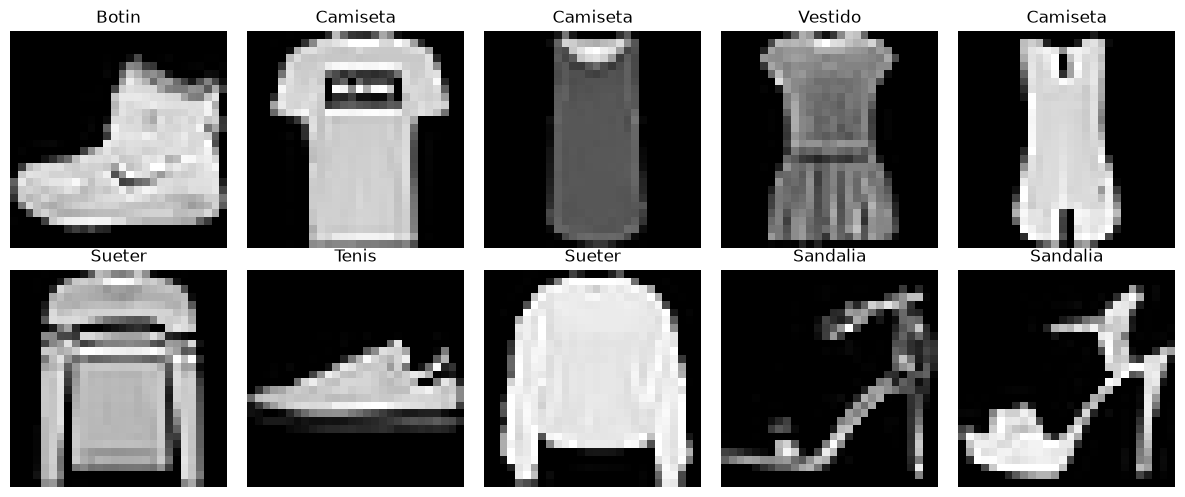

In [5]:
# Mostramos ejemplos de las prendas del dataset

prendas = [
    "Camiseta",
    "Pantalon",
    "Sueter",
    "Vestido",
    "Abrigo",
    "Sandalia",
    "Camisa",
    "Tenis",
    "Bolsa",
    "Botin"
]

plt.figure(figsize=(12, 5))

for i in range(10):
    imagen, etiqueta = datos_entrenamiento[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(imagen, cmap='gray')
    plt.title(prendas[etiqueta])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
# Convertimos las imagenes en datos numericos para utilizar KNN

imagenes_entrenamiento = datos_entrenamiento.data.numpy()
etiquetas_entrenamiento = datos_entrenamiento.targets.numpy()

imagenes_prueba = datos_prueba.data.numpy()
etiquetas_prueba = datos_prueba.targets.numpy()

imagenes_entrenamiento = imagenes_entrenamiento.reshape(-1, 784)
imagenes_prueba = imagenes_prueba.reshape(-1, 784)

imagenes_entrenamiento = imagenes_entrenamiento.astype(np.float32) / 255
imagenes_prueba = imagenes_prueba.astype(np.float32) / 255

In [7]:
# Separamos los datos que utilizaremos para entrenar y probar el modelo

X_train = imagenes_entrenamiento
y_train = etiquetas_entrenamiento

X_test = imagenes_prueba
y_test = etiquetas_prueba

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (60000, 784)
Datos de prueba: (10000, 784)


In [ ]:
# Creamos el modelo KNN utilizando 5 vecinos

modelo = KNeighborsClassifier(n_neighbors=5)

In [9]:
# Entrenamos el modelo con las imagenes del dataset

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [10]:
# Realizamos las predicciones con las imagenes de prueba

predicciones = modelo.predict(X_test)

print("Predicciones realizadas correctamente")

Predicciones realizadas correctamente


In [11]:
# Calculamos que tan acertadas fueron las predicciones

precision = accuracy_score(y_test, predicciones)

print("Precision del modelo:", round(precision * 100, 2), "%")

Precision del modelo: 85.54 %


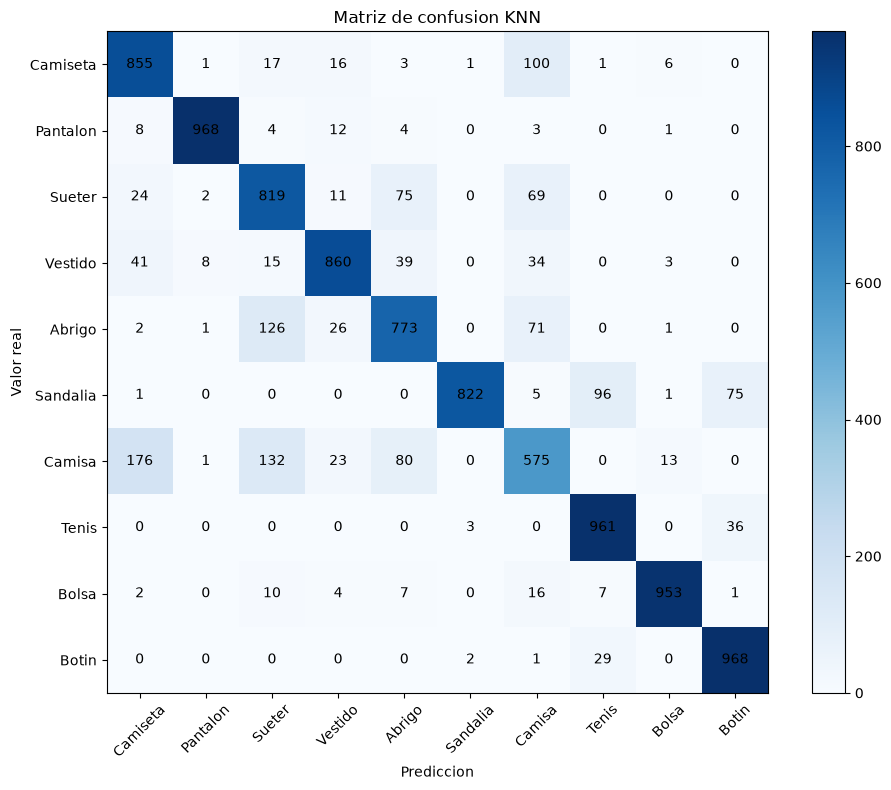

In [12]:
# Mostramos las clasificaciones correctas e incorrectas

matriz = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(10, 8))
plt.imshow(matriz, cmap='Blues')
plt.colorbar()

plt.xticks(range(10), prendas, rotation=45)
plt.yticks(range(10), prendas)

for i in range(10):
    for j in range(10):
        plt.text(j, i, matriz[i, j], ha='center', va='center')

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion KNN")
plt.tight_layout()
plt.show()

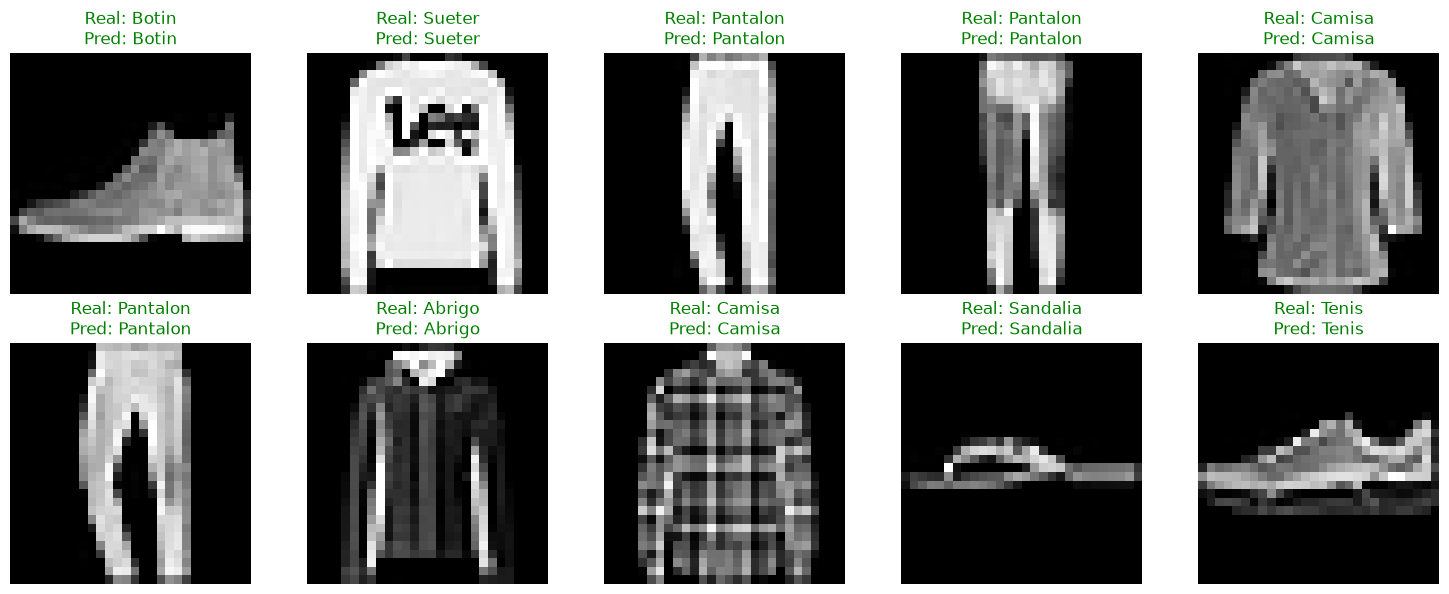

In [13]:
# Mostramos algunas imagenes con su resultado real y prediccion

plt.figure(figsize=(15, 6))

for i in range(10):
    imagen = X_test[i].reshape(28, 28)
    real = y_test[i]
    prediccion = predicciones[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(imagen, cmap='gray')

    if real == prediccion:
        color = 'green'
    else:
        color = 'red'

    plt.title(
        f"Real: {prendas[real]}\nPred: {prendas[prediccion]}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()